
# Classical vs. Quantum Computing: A Big-O Comparison

This notebook pairs classical algorithms with their quantum counterparts, gives the
**full mathematical definition** of each, and visualizes how the underlying
complexity classes (O(1), O(log n), O(√n), O(n), O(n log n), O(n²), O(2ⁿ), ...) scale
against each other.

**Contents:**
1. Big-O refresher and complexity classes
2. The growth-rate landscape (chart)
3. Eight core case studies, each with full classical + quantum derivations
4. Extended taxonomy of quantum algorithms by category, with classical equivalents
   added and several common misconceptions corrected
5. A master summary table covering all ~28 algorithms
6. Caveats every presentation of this material should include
7. Further reading



## 1. Big-O Notation — Formal Definition

$$
f(n) = O(g(n)) \quad \Longleftrightarrow \quad \exists\, c > 0,\ n_0 \in \mathbb{N} \text{ such that } 0 \le f(n) \le c\cdot g(n) \ \ \forall n \ge n_0
$$

In words: $f$ is asymptotically bounded above by a constant multiple of $g$, for all sufficiently large $n$. This is why Big-O is the right tool for comparing classical and quantum algorithms — it isolates the **growth rate**, independent of hardware-specific constants, clock speeds, or gate-fidelity overheads.

Complexity classes referenced throughout this notebook:

| Class | Definition |
|---|---|
| **P** | Decision problems solvable by a deterministic classical Turing machine in time $O(n^k)$ for some constant $k$. |
| **NP** | Decision problems whose *certificates* can be verified in $O(n^k)$ time. |
| **BPP** | Like P, but the algorithm may be randomized, with error probability $\le 1/3$ on every input. |
| **BQP** | Decision problems solvable by a polynomial-size quantum circuit with error probability $\le 1/3$. |
| **#P** | Counting problems: "how many certificates satisfy this?" (e.g. computing the permanent of a matrix is #P-hard). |

$$
\mathbf{P} \subseteq \mathbf{BPP} \subseteq \mathbf{BQP} \subseteq \mathbf{PSPACE}
$$



## 2. The Growth-Rate Landscape

Every Big-O class referenced in this notebook, plotted against a common $n$-axis. The
**left panel** uses a linear $y$-axis to show crossover behavior for small $n$; the
**right panel** uses a logarithmic $y$-axis, the only way to fit $O(2^n)$ on the same
plot as $O(\log n)$ without the exponential curve swallowing everything else.


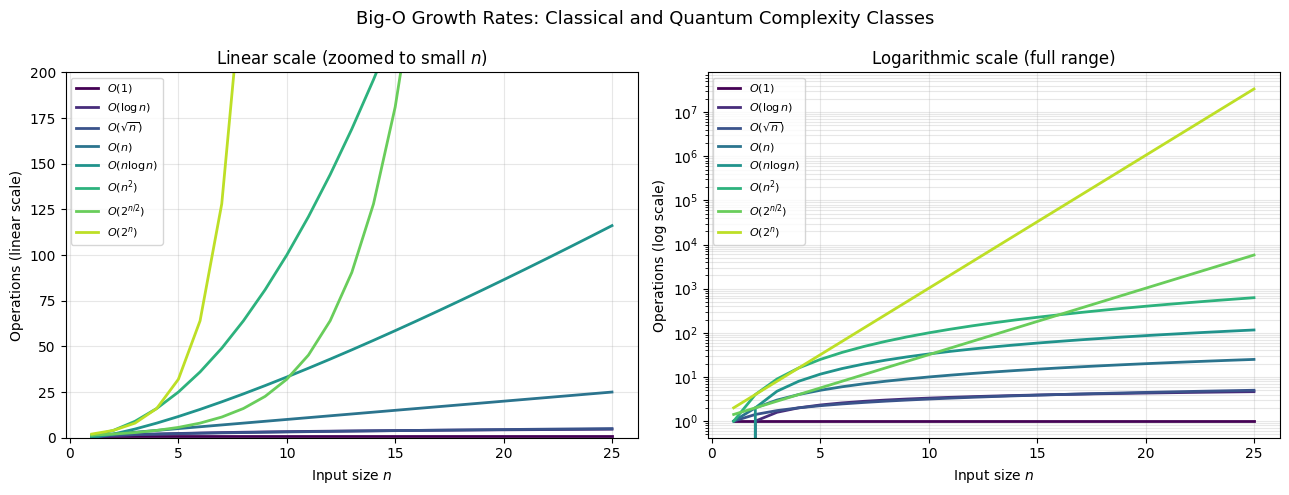

In [1]:

import numpy as np
import matplotlib.pyplot as plt

n = np.arange(1, 26)

functions = {
    r"$O(1)$":            np.ones_like(n, dtype=float),
    r"$O(\log n)$":       np.log2(n),
    r"$O(\sqrt{n})$":     np.sqrt(n),
    r"$O(n)$":            n.astype(float),
    r"$O(n \log n)$":     n * np.log2(n),
    r"$O(n^2)$":          n.astype(float) ** 2,
    r"$O(2^{n/2})$":      2.0 ** (n / 2),
    r"$O(2^n)$":          2.0 ** n,
}

colors = plt.cm.viridis(np.linspace(0, 0.9, len(functions)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for (label, values), c in zip(functions.items(), colors):
    axes[0].plot(n, values, label=label, color=c, linewidth=2)
    axes[1].semilogy(n, values, label=label, color=c, linewidth=2)

axes[0].set_ylim(0, 200)
axes[0].set_xlabel("Input size $n$")
axes[0].set_ylabel("Operations (linear scale)")
axes[0].set_title("Linear scale (zoomed to small $n$)")
axes[0].legend(fontsize=8, loc="upper left")
axes[0].grid(alpha=0.3)

axes[1].set_xlabel("Input size $n$")
axes[1].set_ylabel("Operations (log scale)")
axes[1].set_title("Logarithmic scale (full range)")
axes[1].legend(fontsize=8, loc="upper left")
axes[1].grid(alpha=0.3, which="both")

fig.suptitle("Big-O Growth Rates: Classical and Quantum Complexity Classes", fontsize=13)
fig.tight_layout()
plt.show()



**Reading the chart:** every quantum speedup in this notebook is a move from one curve
to a slower-growing curve — e.g. Grover's algorithm moves you from $O(n)$ down to
$O(\sqrt n)$; Shor's algorithm moves you off the $O(2^n)$-family curve entirely onto a
polynomial curve. On a log scale, $O(2^n)$ vs $O(\mathrm{poly}(n))$ is a *widening*
gap, whereas $O(n)$ vs $O(\sqrt n)$ is a gap of constant ratio in the exponent —
still enormous in absolute terms, but a fundamentally different kind of separation.



## 3. Core Case Studies

Each case study below follows the same structure: problem definition, classical
algorithm with full derivation, quantum algorithm with full derivation, and a boxed
comparison.



### 3.1 Unstructured Search: Linear Scan vs. Grover's Algorithm

**Problem.** Given an oracle $f:\{0,\dots,N-1\}\to\{0,1\}$ with a unique marked item
$x_0$ ($f(x_0)=1$, else $0$), find $x_0$.

**Classical.** Sequential scan: $T_{\text{classical}}(N) = O(N)$, and this is optimal — $\Omega(N)$ is a matching classical lower bound.

**Quantum — Grover's algorithm.**

Initialize the uniform superposition with $n=\log_2 N$ Hadamards:
$$
|s\rangle = H^{\otimes n}|0\rangle^{\otimes n} = \frac{1}{\sqrt{N}}\sum_{x=0}^{N-1}|x\rangle
$$
Oracle (phase flip): $U_f|x\rangle = (-1)^{f(x)}|x\rangle$. Diffusion operator: $U_s = 2|s\rangle\langle s| - I$. Grover iterate: $G = U_s U_f$.

Writing $|s\rangle = \cos\theta\,|\beta\rangle + \sin\theta\,|\gamma\rangle$ with $\theta=\arcsin(1/\sqrt N)$ ($|\gamma\rangle=|x_0\rangle$, $|\beta\rangle$ the orthogonal "bad" subspace), $G$ is a rotation by $2\theta$:
$$
G^t|s\rangle = \cos\big((2t{+}1)\theta\big)|\beta\rangle + \sin\big((2t{+}1)\theta\big)|\gamma\rangle
$$
Maximizing the success amplitude gives the optimal iteration count:
$$
t^{*} \approx \frac{\pi}{4}\sqrt{N} \quad\Longrightarrow\quad T_{\text{Grover}}(N) = O(\sqrt{N})
$$
proven optimal by the Bennett–Bernstein–Brassard–Vazirani lower bound $\Omega(\sqrt N)$.

$$
\boxed{O(N)\ \longrightarrow\ O(\sqrt N)}
$$



### 3.2 Integer Factorization: GNFS vs. Shor's Algorithm

**Problem.** Given composite $N=pq$ ($n=\lceil\log_2 N\rceil$ bits), find $p,q$.

**Classical — General Number Field Sieve.**
$$
T_{\text{GNFS}}(N) = \exp\!\left(\Big(\big(\tfrac{64}{9}\big)^{1/3}{+}o(1)\Big)(\ln N)^{1/3}(\ln\ln N)^{2/3}\right)
$$
sub-exponential, but super-polynomial in $n$.

**Quantum — Shor's algorithm.** Pick random $a$ coprime to $N$; find the order $r$ (smallest $r$ with $a^r\equiv 1 \pmod N$). If $r$ is even and $a^{r/2}\not\equiv -1$, then $p=\gcd(a^{r/2}{-}1,N)$, $q=\gcd(a^{r/2}{+}1,N)$.

Order-finding uses $U_a|y\rangle=|ay \bmod N\rangle$, whose eigenvectors $|u_s\rangle=\frac{1}{\sqrt r}\sum_k e^{-2\pi isk/r}|a^k \bmod N\rangle$ have eigenvalues $e^{2\pi is/r}$. Quantum phase estimation extracts $s/r$, followed by the QFT:
$$
\mathrm{QFT}_M|j\rangle = \frac{1}{\sqrt M}\sum_{k=0}^{M-1} e^{2\pi ijk/M}|k\rangle
$$
and continued fractions recover $r$ from the measured phase.

$$
T_{\text{Shor}}(n) = O\big(n^2\log n\log\log n\big) \qquad \text{(polynomial in the bit-length $n$)}
$$

$$
\boxed{\exp\!\big(O(n^{1/3}\log^{2/3}n)\big)\ \longrightarrow\ O(n^2\log n\log\log n)}
$$



### 3.3 The Fourier Transform: FFT vs. QFT

**Problem.** Given $x_0,\dots,x_{N-1}\in\mathbb{C}$, compute $X_k=\sum_{n=0}^{N-1} x_n e^{-2\pi ikn/N}$.

**Classical — FFT (Cooley–Tukey).** Splitting even/odd indices gives the recursion
$$
T(N)=2T(N/2)+O(N) \implies T_{\text{FFT}}(N)=O(N\log N)
$$

**Quantum — QFT.** The unitary $\mathrm{QFT}:|x\rangle\mapsto\frac{1}{\sqrt N}\sum_k e^{2\pi ixk/N}|k\rangle$ factors as a product state over $n=\log_2N$ qubits:
$$
\mathrm{QFT}|x\rangle=\frac{1}{2^{n/2}}\bigotimes_{j=1}^n\Big(|0\rangle+e^{2\pi i\,0.x_jx_{j+1}\cdots x_n}|1\rangle\Big)
$$
implemented with $n$ Hadamards and controlled-phase gates $R_k=\mathrm{diag}(1,e^{2\pi i/2^k})$:
$$
T_{\text{QFT-circuit}}(N)=O\big((\log N)^2\big)\ \text{gates}
$$

**Caveat.** This speeds up manipulating amplitudes, not extracting all $N$ classical
output values — reading those out costs $\Omega(N)$ measurements regardless.

$$
\boxed{O(N\log N)\ \longrightarrow\ O((\log N)^2)\ \text{(gate count; readout still costs $\Omega(N)$)}}
$$



### 3.4 Brute-Force Search / SAT: Exhaustive Search vs. Grover-Accelerated Search

**Problem.** Decide $\exists\,x\in\{0,1\}^n:\phi(x)=1$ for CNF formula $\phi$.

**Classical.** Evaluate $\phi$ on all $N=2^n$ assignments: $T_{\text{classical}}(n)=O(2^n)$.

**Quantum.** Apply Grover's algorithm (Section 3.1) with oracle $f(x)=\phi(x)$ over $N=2^n$ assignments:
$$
T_{\text{quantum}}(n)=O(\sqrt N)=O(2^{n/2})
$$

$$
\boxed{O(2^n)\ \longrightarrow\ O(2^{n/2})}
$$

This is a quadratic reduction **of the exponent**, not a change of complexity class —
SAT remains exponential quantumly, and $\mathbf{P}=\mathbf{NP}$ is not implied.



### 3.5 Linear Systems: Gaussian Elimination vs. HHL

**Problem.** Solve $A\vec x=\vec b$ for Hermitian $N\times N$ matrix $A$.

**Classical — Gaussian elimination.** $T_{\text{Gaussian}}(N)=O(N^3)$. (Sparse iterative methods: $O(N\,s\,\kappa)$, $s$=sparsity, $\kappa$=condition number.)

**Quantum — HHL.** Diagonalize $A=\sum_j\lambda_j|u_j\rangle\langle u_j|$, $|b\rangle=\sum_j\beta_j|u_j\rangle$. Phase estimation with $e^{iAt}$ gives $\sum_j\beta_j|u_j\rangle|\lambda_j\rangle$; a controlled ancilla rotation by angle $\propto 1/\lambda_j$ followed by uncomputation and post-selection leaves
$$
|x\rangle \propto \sum_j \frac{\beta_j}{\lambda_j}|u_j\rangle = A^{-1}|b\rangle
$$
$$
T_{\text{HHL}}(N)=O\!\big(\log(N)\cdot s^2\kappa^2/\epsilon\big)
$$

**Caveat.** HHL outputs the quantum *state* $|x\rangle$, not the classical vector — reading out all $N$ components costs $O(N)$ again.

$$
\boxed{O(N^3)\ \longrightarrow\ O(\log N)\ \text{(state, not vector; needs sparse, well-conditioned $A$)}}
$$



### 3.6 Simulating Quantum Systems: Dense Classical Simulation vs. Trotterization

**Problem.** Compute $|\psi(t)\rangle=e^{-iHt}|\psi(0)\rangle$ for an $n$-qubit Hamiltonian $H$.

**Classical.** State vector has $2^n$ amplitudes; dense matrix-vector product costs $T_{\text{classical}}(n)=O(2^{2n})$, space $O(2^n)$.

**Quantum — Trotter–Suzuki.** With $H=\sum_{k=1}^L H_k$ (local terms):
$$
e^{-iHt}\approx\Big(\prod_k e^{-iH_kt/r}\Big)^r, \qquad \text{error}=O\!\Big(\tfrac{t^2}{r}\sum_{j<k}\|[H_j,H_k]\|\Big)
$$
Choosing $r=O(t^2/\epsilon)$ gives error $\epsilon$; each local term costs $O(1)$ gates:
$$
T_{\text{quantum}}(n,t,\epsilon)=O\!\big(\mathrm{poly}(n)\cdot t^2/\epsilon\big)
$$

$$
\boxed{O(2^{2n})\ \longrightarrow\ O(\mathrm{poly}(n))}
$$

The most robust speedup here: no special problem structure required, and no expensive read-out of an exponentially large answer.



### 3.7 Sorting: The Control Case (No Quantum Speedup)

**Problem.** Sort $N$ comparable elements.

**Classical — merge sort.** $T(N)=2T(N/2)+O(N)\implies O(N\log N)$, **provably optimal**: a comparison-sort decision tree with $N!$ leaves needs depth $d\ge\log_2(N!)=\Omega(N\log N)$ (Stirling's approximation).

**Quantum.** No general speedup: Grover's $\Omega(\sqrt N)$ *query* lower bound applies per search, and $\Omega(N)$ element placements are still needed. (Quantum minimum-finding, Dürr–Høyer, finds one minimum in $O(\sqrt N)$, but repeating it for a full sort costs $O(N^{1.5})$ — *worse* than classical for large $N$.)

$$
\boxed{O(N\log N)\ \longrightarrow\ O(N\log N)\ \textbf{(no improvement)}}
$$

Included deliberately as a control case: quantum speedups need specific structure (oracle access, periodicity, tensor-product state spaces), not just "being quantum."



### 3.8 Element Distinctness: Sort-and-Compare vs. Quantum Walk (Ambainis)

**Problem.** Given $N$ items, determine if any two are equal.

**Classical.** Sort ($O(N\log N)$) then scan: $T_{\text{classical}}(N)=O(N\log N)$.

**Quantum — Ambainis's quantum walk.** A quantum walk on the Johnson graph $J(N,r)$ with $r=N^{2/3}$, using quantum-walk search (generalizing Grover to structured graphs), achieves
$$
T_{\text{quantum}}(N)=O(N^{2/3})
$$
proven optimal by a matching $\Omega(N^{2/3})$ lower bound (Aaronson–Shi).

$$
\boxed{O(N\log N)\ \longrightarrow\ O(N^{2/3})}
$$



## 4. Extended Taxonomy: Quantum Algorithms by Category, with Classical Equivalents

This section organizes the broader quantum-algorithms landscape into the six standard
categories, gives each entry's mathematical definition, and — as requested — adds the
**classical equivalent algorithm and its complexity** for every entry. Several
corrections and clarifications to a common simplified version of this taxonomy are
flagged explicitly as **Note** blocks; a summary of all corrections is in
Section 4.7.



### 4.1 Foundational & Oracle Algorithms

#### Deutsch–Jozsa
**Problem.** $f:\{0,1\}^n\to\{0,1\}$, promised constant or balanced. Decide which.

**Quantum.** $H^{\otimes n}U_fH^{\otimes n}|0\rangle^{\otimes n}$, measure; amplitude of $|0\rangle^{\otimes n}$ is $\frac{1}{2^n}\sum_x(-1)^{f(x)} = \pm1$ (constant) or $0$ (balanced).
$$
T_{\text{quantum}} = O(1)\ \text{query (exact, deterministic)}
$$

**Classical equivalent.** Deterministic exact algorithm: must query more than half the domain, $\Theta(2^n)$ worst case. A *randomized bounded-error* classical algorithm (sample $k$ random points, check consistency) also solves it in $O(1)$ queries.

> **Note (correction to common presentations):** the clean "exponential" advantage of Deutsch–Jozsa is specifically in the *exact/deterministic* query model ($O(1)$ vs $\Theta(2^n)$); against randomized classical algorithms with bounded error, the gap disappears (both are $O(1)$).

#### Bernstein–Vazirani
**Problem.** $f(x)=s\cdot x \bmod 2$, hidden $s\in\{0,1\}^n$. Find $s$.

**Quantum.**
$$
H^{\otimes n}U_fH^{\otimes n}|0\rangle^{\otimes n} = |s\rangle \quad\Longrightarrow\quad T_{\text{quantum}}=O(1)\ \text{query}
$$

**Classical equivalent.** Query $e_1,\dots,e_n$ to learn each bit: $T_{\text{classical}}=\Theta(n)$ (information-theoretically necessary — each classical query yields $\le 1$ bit).

$$
\boxed{\Theta(n) \longrightarrow O(1)}
$$

#### Simon's Algorithm
**Problem.** $f:\{0,1\}^n\to\{0,1\}^n$, 2-to-1 with $f(x)=f(y)\iff y=x\oplus s$, $s\ne 0$. Find $s$.

**Quantum.** Each round: $H^{\otimes n}U_fH^{\otimes n}$, measure — yields $y$ with $y\cdot s\equiv 0\pmod 2$. After $O(n)$ rounds, solve the linear system over $\mathrm{GF}(2)$ (Gaussian elimination, $O(n^3)$):
$$
T_{\text{quantum}} = O(n)\ \text{queries} + O(n^3)\ \text{classical post-processing}
$$

**Classical equivalent.** Birthday-paradox collision search over a 2-to-1 function on domain $2^n$: $\Omega(2^{n/2})$ queries required.

$$
\boxed{\Theta(2^{n/2}) \longrightarrow O(n)}
$$

#### Hidden Subgroup Problem (HSP)
**Problem.** $f:G\to X$ constant on (and injective across) cosets of unknown $H\le G$. Find generators of $H$.

**Quantum (abelian $G$).** Solved via the QFT over $G$ in $O(\mathrm{poly}(\log|G|))$ — this single framework generalizes Simon's problem ($G=(\mathbb Z_2)^n$) and Shor's problem ($G=\mathbb Z_N$).

**Classical equivalent.** Exponential in general (e.g. $\Theta(2^{n/2})$ for the Simon's-problem instance above).

> **Note (correction):** the **non-abelian HSP** — whose efficient solution would resolve Graph Isomorphism via $G=S_n$ (the symmetric group) — has **no known efficient quantum algorithm**, despite two decades of effort. The framework's success is currently limited to the abelian case; presenting HSP as a solved general-purpose tool overstates the state of the art.



### 4.2 Quantum Fourier Transform & Algebraic Algorithms

#### Shor's Algorithm
Covered fully in Section 3.2: $\exp\!\big(O(n^{1/3}\log^{2/3}n)\big)\to O(n^2\log n\log\log n)$.

#### Quantum Phase Estimation (QPE)
**Problem.** Given unitary $U$, eigenpair $U|u\rangle=e^{2\pi i\theta}|u\rangle$, estimate $\theta$.

**Quantum.** $n$ ancillas, controlled-$U^{2^k}$, inverse QFT:
$$
H^{\otimes n}|0\rangle^{\otimes n}|u\rangle \xrightarrow{\text{ctrl-}U^{2^k}} \frac{1}{\sqrt{2^n}}\sum_{j=0}^{2^n-1}e^{2\pi i\theta j}|j\rangle|u\rangle \xrightarrow{\mathrm{QFT}^{-1}} |\tilde\theta\rangle|u\rangle
$$
$$
T_{\text{quantum}} = O(1/\epsilon)\ \text{controlled-}U\ \text{calls} + O(\log^2(1/\epsilon))\ \text{QFT gates}
$$

**Classical equivalent.** Full eigendecomposition of an $N\times N$ matrix: $O(N^3)$ (or Lanczos/power iteration, $O(N)$ per iteration, iteration count set by the spectral gap). QPE's advantage is entangled with efficient implementability of $U$ (e.g. via Hamiltonian simulation, Section 3.6).

#### Hadamard Test & Swap Test
**Hadamard test** (ancilla $|0\rangle$, controlled-$U$ on $|\psi\rangle$):
$$
P(0)-P(1) = \mathrm{Re}\langle\psi|U|\psi\rangle
$$
**Swap test** (ancilla $|0\rangle$, controlled-SWAP on $|\phi\rangle,|\psi\rangle$):
$$
P(0) = \tfrac12 + \tfrac12|\langle\phi|\psi\rangle|^2
$$
$$
T_{\text{quantum}} = O(1)\ \text{depth per shot},\ O(1/\epsilon^2)\ \text{shots for precision}\ \epsilon
$$

**Classical equivalent.** If $|\phi\rangle,|\psi\rangle$ are explicit length-$N=2^n$ vectors, computing $\langle\phi|\psi\rangle$ exactly costs $O(N)$. The quantum tests trade this exact $O(N)$ computation for a *statistical* $O(1/\epsilon^2)$-shot estimate on states that were never classically written down.

#### Aharonov–Jones–Landau
**Problem.** Approximate the Jones polynomial $V_L(e^{2\pi i/k})$ of a link $L$ (braid word, length $n$) to additive precision.

**Quantum.** $T_{\text{quantum}}=O(\mathrm{poly}(n,k))$ — this problem is **BQP-complete**.

**Classical equivalent.** Exact evaluation is **#P-hard** (Jaeger–Vertigan–Welsh); no known polynomial classical algorithm even for additive approximation. $T_{\text{classical}} = O(2^n)$-type state enumeration.



### 4.3 Search & Amplitude Amplification

#### Amplitude Amplification (general form)
**Problem.** Given $\mathcal A|0\rangle=\sqrt a\,|\mathrm{good}\rangle+\sqrt{1-a}\,|\mathrm{bad}\rangle$, boost $a$ toward 1.

**Quantum.** Grover-like iterate $Q=-\mathcal A S_0\mathcal A^{-1}S_\chi$, applied $O(1/\sqrt a)$ times.

**Classical equivalent.** If $\mathcal A$ is a randomized classical procedure succeeding with probability $a$: expected repeats $=O(1/a)$ (geometric distribution).

$$
\boxed{O(1/a) \longrightarrow O(1/\sqrt a)}
$$

#### Quantum Counting Algorithm
**Problem.** Estimate $M$ = number of marked items among $N$ ($a=M/N$).

**Quantum.** QPE (Section 4.2) applied to the Grover iterate's eigenvalues ($\sin^2\theta=M/N$):
$$
T_{\text{quantum}} = O(\sqrt{N/M})\ \text{for constant relative error}
$$

**Classical equivalent.** Random sampling: $\Theta(N/M)$ samples for the same relative error (Chernoff bound on a Bernoulli($M/N$) estimator).

$$
\boxed{\Theta(N/M) \longrightarrow O(\sqrt{N/M})}
$$

#### BHT Algorithm (Brassard–Høyer–Tapp)
**Problem.** $f$ promised 2-to-1 (or $r$-to-1) on domain $N$; find a colliding pair.

**Quantum.** Classically query $k=N^{1/3}$ random points into a table, then Grover-search the rest for a match ($O(\sqrt{N/k})$ queries); balancing gives:
$$
T_{\text{quantum}} = O(N^{1/3})\ \text{queries and quantum-accessible memory}
$$

**Classical equivalent.** Birthday attack: $\Theta(\sqrt N)$ queries and space.

$$
\boxed{\Theta(\sqrt N) \longrightarrow O(N^{1/3})}
$$

> **Note:** don't confuse this with Element Distinctness (Section 3.8): BHT assumes a *promised* 2-to-1 structure (e.g. hash collisions) and achieves the stronger $O(N^{1/3})$; unstructured Element Distinctness only achieves $O(N^{2/3})$.



### 4.4 Quantum Simulation & Linear Algebra

#### Hamiltonian Simulation: Trotterization vs. Quantum Signal Processing
Trotterization is covered in Section 3.6: $T_{\text{Trotter}}=O(\mathrm{poly}(n)\cdot t^2/\epsilon)$.

The modern **Quantum Signal Processing / qubitization** approach (Low & Chuang) achieves near-optimal scaling in evolution time $t$:
$$
T_{\text{QSP}} = O\!\left(\alpha t + \frac{\log(1/\epsilon)}{\log\log(1/\epsilon)}\right)
$$
($\alpha$ = normalization from the Hamiltonian's block-encoding), matching the $\Omega(t)$ lower bound from the no-fast-forwarding theorem — i.e. this is essentially *optimal*, not just an improvement.

**Classical equivalent.** Same as Section 3.6: $O(2^{2n})$ dense simulation.

#### HHL Algorithm
Covered fully in Section 3.5: $O(N^3)\to O(\log N)$ (with the state-vs-vector caveat).

#### Quantum Singular Value Transformation (QSVT)
**Problem.** Given a block-encoding unitary $U_A$ of $A/\alpha$, apply a degree-$d$ polynomial transform $P(A)$ to $A$'s singular values.

**Quantum.** Alternating applications of $U_A,U_A^\dagger$ and single-qubit phase rotations $R(\phi_k)$ realize $P^{(SV)}(A)$ for a phase sequence $\{\phi_k\}_{k=1}^d$ determined by $P$:
$$
T_{\text{quantum}} = O(d)\ \text{calls to}\ U_A,U_A^\dagger, \qquad d = O(\mathrm{poly}\log(1/\epsilon))\ \text{typically}
$$
This single framework recovers Grover's ($P\approx\mathrm{sign}$), Hamiltonian simulation ($P\approx e^{ix}$), and HHL ($P(x)\approx1/x$) as special cases.

**Classical equivalent.** Task-dependent: from $O(N)$ (sparse matrix-vector product, degree-1 $P$) to $O(N^3)$ (dense eigendecomposition for general $f(A)$) — always scaling with matrix dimension $N$ rather than $\log N$ or $\mathrm{poly}(d)$.



### 4.5 Optimization & Variational (Hybrid, NISQ) Algorithms

> **Note (important correction to the framing of this category):** unlike Sections
> 4.1–4.4, the algorithms below are **heuristic, near-term (NISQ) hybrid algorithms
> with no proven worst-case complexity advantage** over the best classical methods.
> Their motivation is architectural — they run on noisy hardware today — rather than a
> proven asymptotic separation. Presenting them as tier-equivalent to Shor's or
> Grover's algorithm (as is common in simplified overviews) overstates their
> theoretical standing; their advantage, if any, is empirical and problem-specific.

#### Variational Quantum Eigensolver (VQE)
**Problem.** Estimate the ground-state energy $E_0$ of Hamiltonian $H=\sum_j c_jP_j$ (Pauli decomposition).

**Quantum.**
$$
E_0 \approx \min_{\vec\theta}\langle\psi(\vec\theta)|H|\psi(\vec\theta)\rangle
$$
each $\langle P_j\rangle$ measured via Hadamard-test-style circuits (Section 4.2), $\vec\theta$ updated by a classical optimizer.
$$
T_{\text{quantum, per iteration}} = O(M/\epsilon^2)\ \text{shots}\ (M{=}\#\text{Pauli terms, up to}\ O(n^4)), \quad O(\mathrm{poly}(n))\ \text{circuit depth}
$$

**Classical equivalent.** Exact diagonalization (Full Configuration Interaction): $O(e^{cn})$. Polynomial approximate methods also exist (Coupled-Cluster CCSD(T) $\sim O(n^7)$, DFT $\sim O(n^3)$) with different, sometimes uncontrolled, accuracy guarantees.

#### Quantum Approximate Optimization Algorithm (QAOA)
**Problem.** Approximately solve a combinatorial optimization problem, e.g. Max-Cut.

**Quantum.**
$$
|\vec\gamma,\vec\beta\rangle = \prod_{k=1}^p e^{-i\beta_kH_M}e^{-i\gamma_kH_C}|s\rangle,\qquad H_C=\sum_{(i,j)\in E}\frac{1-Z_iZ_j}{2}
$$
classically optimized over $(\vec\gamma,\vec\beta)$ to maximize $\langle H_C\rangle$; circuit depth $O(p\cdot|E|)$.

**Classical equivalent.** Exact Max-Cut is NP-hard ($O(2^n)$ brute force); the **Goemans–Williamson** SDP-rounding algorithm gives a *guaranteed* 0.878-approximation in polynomial time $O(n^{3.5})$ — for $p{=}1$, QAOA is known to sometimes *underperform* this classical benchmark.

#### Quantum Annealing
**Problem.** Find the ground state of an Ising/QUBO Hamiltonian $H_P$.

**Quantum.** Adiabatic path $H(s)=(1-s)H_0+sH_P$, $s=t/T$; the adiabatic theorem requires
$$
T = O\!\left(\frac{\max_s\|dH/ds\|}{\min_s\Delta(s)^2}\right)
$$
$\Delta(s)$ = spectral gap. $T=O(\mathrm{poly}(n))$ **if** $\Delta_{\min}$ shrinks only polynomially — but for many hard instances $\Delta_{\min}=O(2^{-n})$, forcing $T=O(2^{2n})$: **no guaranteed speedup**.

**Classical equivalent.** Simulated annealing (also exponential worst-case) or exact QUBO solvers, $O(2^n)$.



### 4.6 Quantum Machine Learning & Sampling

#### Quantum SVM / Quantum Neural Networks
**Problem.** Classify data using a quantum feature map $x\mapsto|\phi(x)\rangle$.

**Quantum.** Kernel $K(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2$ estimated via the swap test (Section 4.2):
$$
T_{\text{quantum}} = O(N^2/\epsilon^2)\ \text{total for}\ N\ \text{training examples}
$$

**Classical equivalent.** Classical kernel SVM: $O(N^2)$–$O(N^3)$ for kernel matrix construction and the dual quadratic program.

> **Note (correction):** several early claims of *exponential* quantum ML speedup (e.g. HHL-based recommendation systems) were subsequently **"dequantized."** Tang (2018) gave a classical randomized algorithm matching the claimed exponential speedup, under the same $\ell^2$-norm sampling-access assumption on the data — reducing the gap to polynomial. Quantum ML speedup claims should always be checked against this dequantization literature.

#### Boson Sampling
**Problem.** Sample photon-detection patterns from an $n$-photon, $m$-mode linear-optical network with unitary $U$; the probability of pattern $S$ is
$$
P(S) = \frac{|\mathrm{Perm}(U_S)|^2}{s_1!\,s_2!\cdots s_m!}
$$
($U_S$ an $n\times n$ submatrix of $U$ selected by $S$).

**Quantum (physical).** $T_{\text{quantum}}=O(\mathrm{poly}(n,m))$ — essentially the transit time of light through the device.

**Classical equivalent.** Exact evaluation of a single probability requires $\mathrm{Perm}(U_S)$, **#P-hard**; best known exact algorithm (Ryser's formula) costs $O(n\,2^n)$. Approximate *sampling* from the full distribution is *conjectured* — under the Permanent-of-Gaussians and Anti-Concentration conjectures — to require classical super-polynomial time.

> **Note:** Boson Sampling solves no practically useful problem; it exists to demonstrate a quantum-advantage separation under plausible complexity-theoretic assumptions, not a proven worst-case gap — an important distinction from Shor's or Grover's algorithms.

#### Quantum Random Walks (Discrete & Continuous)
**Continuous-time walk generator:** $H=-\gamma A$ ($A$ = graph adjacency matrix), $|\psi(t)\rangle=e^{-iHt}|\psi(0)\rangle$, vs. the classical diffusion equation $\dot p=-\gamma Lp$ ($L$ = graph Laplacian).

**General speedup.** Spatial search on many graphs achieves $O(\sqrt N)$ hitting time (generalizing Grover) vs. classical $O(N)$.

**Sharpest, rigorously proven example — the glued-trees problem** (Childs, Cleve, Deotto, Farhi, Gutmann, Spielman, 2003): a continuous-time quantum walk crosses a graph built from two depth-$n$ binary trees glued at their leaves by a random cycle, entrance to exit, in $O(\mathrm{poly}(n))$ time. **Any classical algorithm** (even randomized, with local exploration) provably requires
$$
\Omega(2^{n/6})\ \text{queries}
$$
— a proven exponential oracle separation, in contrast to the conjectural separations above (Boson Sampling) or the heuristic ones (Section 4.5).

**Classical equivalent.** Classical random walk / local graph search: $O(\mathrm{poly}(n))$ generically, $\Omega(2^{n/6})$ specifically for the glued-trees construction.



### 4.7 Summary of Corrections Made to the Original Category List

The category structure (six branches) from the source list is sound and is preserved
above. The following specific corrections and additions were made:

1. **Deutsch–Jozsa:** clarified that its $O(1)$-vs-exponential separation holds only
   against *exact/deterministic* classical algorithms — a randomized classical
   algorithm also achieves $O(1)$ with bounded error.
2. **Simon's algorithm / HSP:** added the missing concrete complexities
   ($O(n)$ quantum vs. $\Theta(2^{n/2})$ classical), and flagged that the
   **non-abelian HSP remains unsolved** in general (relevant to Graph Isomorphism) —
   the framework's efficiency is currently limited to abelian groups.
3. **Quantum Counting / BHT:** the original list named these without complexity
   figures; added $O(\sqrt{N/M})$ and $O(N^{1/3})$ respectively, with classical
   baselines, and clarified how BHT differs from Element Distinctness.
4. **Aharonov–Jones–Landau:** clarified this is **BQP-complete**, and that exact
   classical evaluation is **#P-hard** — context missing from the original entry.
5. **VQE / QAOA / Quantum Annealing:** added the essential caveat that these NISQ-era
   algorithms have **no proven worst-case speedup** — a qualitatively different
   category from Sections 4.1–4.4, which the original flat list did not distinguish.
6. **QSVM / QNN:** added the **dequantization** caveat (Tang, 2018) — several claimed
   exponential quantum ML speedups were later matched by classical algorithms.
7. **Boson Sampling:** clarified that its "advantage" is a complexity-theoretic
   *conjecture*, not a proven separation, and that it targets a supremacy
   demonstration rather than a useful computational task.
8. **Quantum Random Walks:** replaced the vague "speedups for graph traversal" with
   the concrete, *rigorously proven* glued-trees exponential separation.



## 5. Master Summary Table

All algorithms from Sections 3 and 4 in one place, with classical equivalents and a
note on whether the separation is **proven**, **conjectured** (under standard
complexity assumptions), or **heuristic** (empirical, no worst-case guarantee).


In [2]:

import pandas as pd

rows = [
    # Category, Algorithm, Classical equivalent + complexity, Quantum complexity, Speedup type, Status
    ["Core case study", "Unstructured search (Grover)",       "Linear scan — O(N)",                 "O(sqrt(N))",           "Quadratic",              "Proven (matching lower bound)"],
    ["Core case study", "Factoring (Shor)",                   "GNFS — sub-exponential",              "O(poly(n))",            "Exponential",            "Proven"],
    ["Core case study", "Fourier transform (QFT)",             "FFT — O(N log N)",                    "O(log^2 N)*",           "Exponential (caveat)",   "Proven (gate count only)"],
    ["Core case study", "SAT / brute-force search",           "Exhaustive search — O(2^n)",           "O(2^(n/2))",            "Quadratic (in exponent)","Proven"],
    ["Core case study", "Linear systems (HHL)",                "Gaussian elim. — O(N^3)",              "O(log N)*",             "Exponential (caveat)",   "Proven (state, not vector)"],
    ["Core case study", "Quantum system simulation",           "Dense sim. — O(2^(2n))",               "O(poly(n))",            "Exponential",            "Proven"],
    ["Core case study", "Sorting",                             "Merge sort — O(N log N)",              "O(N log N)",            "None",                   "Proven (no speedup)"],
    ["Core case study", "Element distinctness (Ambainis)",     "Sort & compare — O(N log N)",          "O(N^(2/3))",            "Polynomial",             "Proven (matching lower bound)"],

    ["Foundational/Oracle", "Deutsch-Jozsa",                   "Exact: Theta(2^n); randomized: O(1)",  "O(1)",                  "Exp. (exact model only)","Proven"],
    ["Foundational/Oracle", "Bernstein-Vazirani",              "Theta(n)",                             "O(1)",                  "Linear-to-constant",     "Proven"],
    ["Foundational/Oracle", "Simon's algorithm",               "Theta(2^(n/2))",                       "O(n)",                  "Exponential",            "Proven"],
    ["Foundational/Oracle", "Hidden Subgroup Problem (abelian)","Exponential (e.g. Simon's instance)", "O(poly(log|G|))",       "Exponential",            "Proven (abelian only)"],

    ["QFT/Algebraic", "Quantum Phase Estimation",               "Eigendecomposition — O(N^3)",         "O(1/eps) ctrl-U calls", "Depends on U",            "Proven (given efficient U)"],
    ["QFT/Algebraic", "Hadamard / Swap test",                   "Exact inner product — O(N)",          "O(1/eps^2) shots",      "Space vs. statistical",   "Proven"],
    ["QFT/Algebraic", "Aharonov-Jones-Landau",                  "#P-hard exact; O(2^n) enumeration",   "O(poly(n,k))",          "Exponential",             "Proven (BQP-complete)"],

    ["Search/Amp. Amp.", "Amplitude Amplification (general)",  "O(1/a) repetitions",                  "O(1/sqrt(a))",          "Quadratic",               "Proven"],
    ["Search/Amp. Amp.", "Quantum Counting",                   "Theta(N/M) samples",                  "O(sqrt(N/M))",          "Quadratic",               "Proven"],
    ["Search/Amp. Amp.", "BHT collision finding",              "Birthday attack — Theta(sqrt(N))",    "O(N^(1/3))",            "Polynomial",              "Proven"],

    ["Sim./Linear Algebra", "Hamiltonian sim. (QSP/qubitization)","Dense sim. — O(2^(2n))",            "O(alpha t + log(1/eps))","Exponential",             "Proven (near-optimal)"],
    ["Sim./Linear Algebra", "QSVT (framework)",                 "O(N) to O(N^3) depending on task",    "O(d) block-encoding calls","Task-dependent",         "Proven (unifies several)"],

    ["Optimization/Variational", "VQE",                        "Full CI — O(exp(n)); CCSD(T) ~O(n^7)","No proven bound",       "Heuristic",               "No proof (NISQ heuristic)"],
    ["Optimization/Variational", "QAOA",                        "Goemans-Williamson SDP — O(n^3.5), 0.878-approx.","No proven bound","Heuristic",            "No proof (NISQ heuristic)"],
    ["Optimization/Variational", "Quantum Annealing",           "Simulated annealing — O(2^n) worst case","No guaranteed bound","Heuristic",              "No proof (gap-dependent)"],

    ["QML/Sampling", "QSVM / QNN",                              "Classical kernel SVM — O(N^2)-O(N^3)","O(N^2/eps^2)",          "Polynomial (often dequantized)","Caveat: dequantization"],
    ["QML/Sampling", "Boson Sampling",                          "#P-hard exact; O(n*2^n) exact",       "O(poly(n,m)) sampling", "Conjectured exponential", "Conjectured (not proven)"],
    ["QML/Sampling", "Quantum Random Walk (glued trees)",       "Local search — Omega(2^(n/6))",       "O(poly(n))",            "Exponential",             "Proven (oracle separation)"],
]

master = pd.DataFrame(rows, columns=["Category", "Algorithm", "Classical equivalent", "Quantum complexity", "Speedup type", "Proof status"])
pd.set_option("display.max_colwidth", 45)
pd.set_option("display.width", 160)
master


,Category,Algorithm,Classical equivalent,Quantum complexity,Speedup type,Proof status
0,Core case study,Unstructured search (Grover),Linear scan — O(N),O(sqrt(N)),Quadratic,Proven (matching lower bound)
1,Core case study,Factoring (Shor),GNFS — sub-exponential,O(poly(n)),Exponential,Proven
2,Core case study,Fourier transform (QFT),FFT — O(N log N),O(log^2 N)*,Exponential (caveat),Proven (gate count only)
3,Core case study,SAT / brute-force search,Exhaustive search — O(2^n),O(2^(n/2)),Quadratic (in exponent),Proven
4,Core case study,Linear systems (HHL),Gaussian elim. — O(N^3),O(log N)*,Exponential (caveat),"Proven (state, not vector)"
5,Core case study,Quantum system simulation,Dense sim. — O(2^(2n)),O(poly(n)),Exponential,Proven
6,Core case study,Sorting,Merge sort — O(N log N),O(N log N),None,Proven (no speedup)
7,Core case study,Element distinctness (Ambainis),Sort & compare — O(N log N),O(N^(2/3)),Polynomial,Proven (matching lower bound)
8,Foundational/Oracle,Deutsch-Jozsa,Exact: Theta(2^n); randomized: O(1),O(1),Exp. (exact model only),Proven
9,Foundational/Oracle,Bernstein-Vazirani,Theta(n),O(1),Linear-to-constant,Proven



\* Caveats regarding state preparation and readout cost apply — see Sections 3.3 and 3.5.



## 6. Visualizing Speedup Magnitude

For a representative input size, classical vs. quantum operation counts on a log scale
(covering the eight core case studies from Section 3).


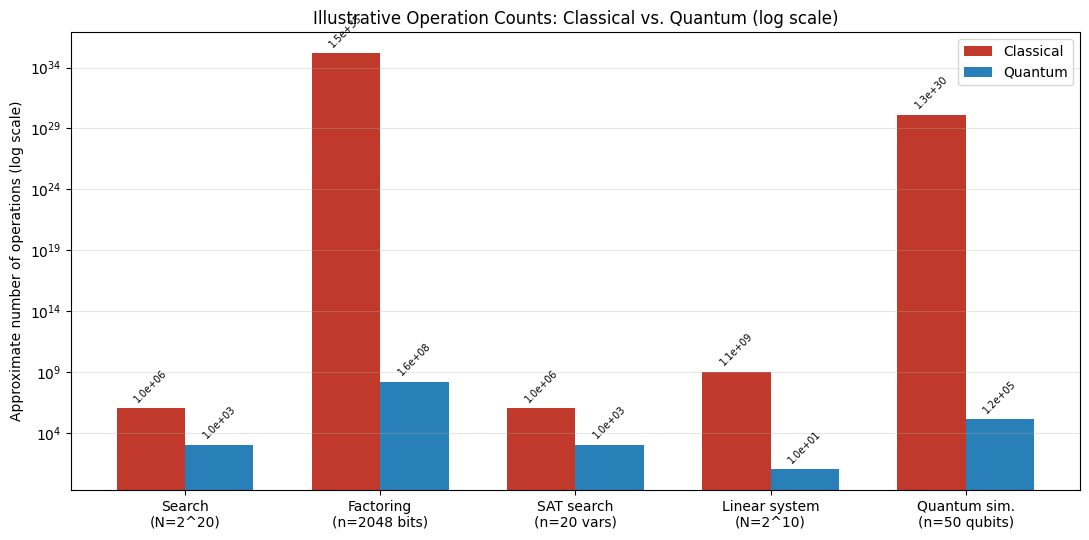

In [3]:

import numpy as np
import matplotlib.pyplot as plt

N_search = float(2**20)
n_bits   = 2048.0
N_lin    = float(2**10)
n_qubits = 50.0

labels = [
    "Search\n(N=2^20)",
    "Factoring\n(n=2048 bits)",
    "SAT search\n(n=20 vars)",
    "Linear system\n(N=2^10)",
    "Quantum sim.\n(n=50 qubits)",
]

classical_ops = [
    N_search,
    np.exp((64/9)**(1/3) * (n_bits*np.log(2))**(1/3) * np.log(n_bits*np.log(2))**(2/3)),
    2.0**20,
    N_lin**3,
    2.0**(2*n_qubits),
]

quantum_ops = [
    np.sqrt(N_search),
    n_bits**2 * np.log2(n_bits) * np.log2(np.log2(n_bits)),
    2.0**10,
    np.log2(N_lin),
    n_qubits**3,
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5.5))
bars1 = ax.bar(x - width/2, classical_ops, width, label="Classical", color="#c0392b")
bars2 = ax.bar(x + width/2, quantum_ops, width, label="Quantum", color="#2980b9")

ax.set_yscale("log")
ax.set_ylabel("Approximate number of operations (log scale)")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Illustrative Operation Counts: Classical vs. Quantum (log scale)")
ax.legend()
ax.grid(axis="y", alpha=0.3, which="both")

for bar in list(bars1) + list(bars2):
    height = bar.get_height()
    ax.annotate(f"{height:.1e}",
                xy=(bar.get_x() + bar.get_width()/2, height),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=7, rotation=45)

fig.tight_layout()
plt.show()



Sorting is omitted here since its bars would be identical — a reminder that the size
of these gaps is entirely problem-dependent, never a generic property of "using a
quantum computer."



## 7. Caveats Every Presentation of This Material Should Include

1. **Oracle/query model vs. real-world cost.** Grover's and Shor's complexities are
   usually stated in a query or gate-count model; real hardware adds overhead from
   error correction and decoherence.
2. **Read-out bottleneck.** QFT and HHL apply to problems where only a summary
   statistic of an exponentially large state is needed — reading out all $N$ classical
   values costs at least $O(N)$ measurements regardless of the transform's own speed.
3. **No universal speedup.** Sorting (Section 3.7) is a clean counterexample.
4. **P vs NP is untouched.** Grover's algorithm gives a quadratic speedup on
   exponential-time brute force but does not imply $\mathbf{BQP}\supseteq\mathbf{NP}$.
5. **Constants matter in practice.** Big-O hides constant factors; for small $n$ a
   classical algorithm can beat a quantum one with better asymptotic complexity.
6. **Proof status varies enormously.** As the "Proof status" column in Section 5
   shows, quantum advantage ranges from *rigorously proven with a matching lower
   bound* (Grover's, Element Distinctness, glued trees) to *proven relative to a
   specific classical algorithm* (Shor's vs. GNFS), to *conjectured under standard
   complexity assumptions* (Boson Sampling), to *purely heuristic with no worst-case
   guarantee* (VQE, QAOA, Quantum Annealing). Treating all of these as equally solid
   is the single most common inaccuracy in popular accounts of quantum computing.
7. **Dequantization is an active, moving target.** Some claimed exponential quantum
   machine-learning speedups have been matched by classical "dequantized" algorithms
   under comparable data-access assumptions — always check whether a claimed speedup
   has survived this scrutiny.



## 8. Further Reading

**Textbook**
- Nielsen, M. A., & Chuang, I. L. *Quantum Computation and Quantum Information*.

**Foundational**
- Deutsch, D., & Jozsa, R. (1992). "Rapid solution of problems by quantum computation."
- Bernstein, E., & Vazirani, U. (1993). "Quantum complexity theory."
- Simon, D. R. (1994). "On the power of quantum computation."

**Algebraic / QFT**
- Shor, P. W. (1997). "Polynomial-Time Algorithms for Prime Factorization and Discrete Logarithms on a Quantum Computer."
- Aharonov, D., Jones, V., & Landau, Z. (2006). "A polynomial quantum algorithm for approximating the Jones polynomial."

**Search / Amplitude Amplification**
- Grover, L. K. (1996). "A fast quantum mechanical algorithm for database search."
- Brassard, G., Høyer, P., Mosca, M., & Tapp, A. (2002). "Quantum Amplitude Amplification and Estimation."
- Brassard, G., Høyer, P., & Tapp, A. (1998). "Quantum cryptanalysis of hash and claw-free functions" (the BHT algorithm).
- Ambainis, A. (2007). "Quantum walk algorithm for element distinctness."
- Dürr, C., & Høyer, P. (1996). "A quantum algorithm for finding the minimum."

**Simulation / Linear Algebra**
- Low, G. H., & Chuang, I. L. (2017). "Optimal Hamiltonian Simulation by Quantum Signal Processing."
- Harrow, A. W., Hassidim, A., & Lloyd, S. (2009). "Quantum algorithm for linear systems of equations."
- Gilyén, A., Su, Y., Low, G. H., & Wiebe, N. (2019). "Quantum singular value transformation."

**Variational / NISQ**
- Peruzzo, A., et al. (2014). "A variational eigenvalue solver on a photonic quantum processor" (VQE).
- Farhi, E., Goldstone, J., & Gutmann, S. (2014). "A Quantum Approximate Optimization Algorithm" (QAOA).
- Goemans, M. X., & Williamson, D. P. (1995). "Improved approximation algorithms for maximum cut..."

**Machine Learning / Sampling**
- Tang, E. (2019). "A quantum-inspired classical algorithm for recommendation systems" (dequantization).
- Aaronson, S., & Arkhipov, A. (2011). "The computational complexity of linear optics" (Boson Sampling).
- Childs, A. M., Cleve, R., Deotto, E., Farhi, E., Gutmann, S., & Spielman, D. A. (2003). "Exponential algorithmic speedup by a quantum walk" (glued trees).
